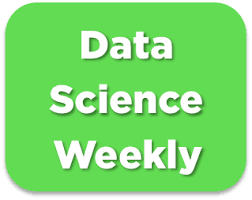

# Challenge : predict conversions 🏆🏆
In this project, you will participate to a machine learning competition like the ones that are organized by https://www.kaggle.com/. You will be able to work with jupyter notebooks as usual, but in the end you'll have to submit your model's predictions to your teacher/TA, so your model's performances will be evaluated in an independent way. The scores achieved by the different teams will be stored into a leaderboard 🏅🏅

## Description of a machine learning challenge 🚴🚴
- In machine learning challenges, the dataset is always separated into to files :
    - *data_train.csv* contains **labelled data**, which means there are both X (explanatory variables) and Y (the target to be predicted). You will use this file to train your model as usual : make the train/test split, preprocessings, assess performances, try different models, fine-tune hyperparameters etc...
    - *data_test.csv* contains "new" examples that have not be used to train the model, in the same format as in *data_train.csv* but it is **unlabeled**, which means the target Y has been removed from the file. Once you've trained a model, you will use *data_test.csv* to make some predictions that you will send to the organizing team. They will then be able to assess the performances of your model in an independent way, by preventing cheating 🤸
- Your model's predictions will be compared to the true labels and releases a leaderboard where the scores of all the teams around the world are stored
- All the participants are informed about the metric that will be used to assess the scores. You have to make sure you're using the same metric to evaluate your train/test performances !

## Company's Description 📇
www.datascienceweekly.org is a famous newsletter curated by independent data scientists. Anyone can register his/her e-mail address on this website to receive weekly news about data science and its applications !

## Project 🚧
The data scientists who created the newsletter would like to understand better the behaviour of the users visiting their website. They would like to know if it's possible to build a model that predicts if a given user will subscribe to the newsletter, by using just a few information about the user. They would like to analyze the parameters of the model to highlight features that are important to explain the behaviour of the users, and maybe discover a new lever for action to improve the newsletter's conversion rate.

They designed a competition aiming at building a model that allows to predict the *conversions* (i.e. when a user will subscribe to the newsletter). To do so, they open-sourced a dataset containing some data about the traffic on their website. To assess the rankings of the different competing teams, they decided to use the **f1-score**.

## Goals 🎯
The project can be cut into four steps :
- Part 1 : make an EDA and the preprocessings and train a baseline model with the file *data_train.csv*
- Part 2 : improve your model's f1-score on your test set (you can try feature engineering, feature selection, regularization, non-linear models, hyperparameter optimization by grid search, etc...)
- Part 3 : Once you're satisfied with your model's score, you can use it to make some predictions with the file *data_test.csv*. You will have to dump the predictions into a .csv file that will be sent to Kaggle (actually, to your teacher/TA 🤓). You can make as many submissions as you want, feel free to try different models !
- Part 4 : Take some time to analyze your best model's parameters. Are there any lever for action that would help to improve the newsletter's conversion rate ? What recommendations would you make to the team ?

## Deliverable 📬
To complete this project, your team should: 
- Create some relevant figures for EDA
- Train at least one model that predicts the conversions and evaluate its performances (f1, confusion matrices)
- Make at least one submission to the leaderboard 
- Analyze your best model's parameters and try to make some recommendations to improve the conversion rate in the future


## Helpers 🦮

To help you with the methodology, we created a template (**02-Conversion_rate_challenge_template.ipynb**) in which all the training/predictions steps are implemented for a very basic model (logistic regression with only one variable). Please use this template and feel free to change the EDA/preprocessing/training steps ! May the force be with you 🧨🧨 

---
# Solution

Notebook built on the Jedha template (`02-Conversion_rate_challenge_template.ipynb`): same data files, same metric (**f1-score**), same submission format (one column `converted`, no index, file `conversion_data_test_predictions_[name].csv`).

Plan:
1. EDA on a sample, data cleaning.
2. Baseline from the template: logistic regression on `total_pages_visited` only.
3. Improvements: all features, decision threshold tuned for f1, degree-2 terms (interactions and squares), gradient boosting with grid search. Model choice on cross-validated f1, check on the held-out test set.
4. Retrain the best models on all labelled data, predict `conversion_data_test.csv`, write the submission files.
5. Analysis of the model's parameters and recommendations to improve the conversion rate.

### Setup
If this cell installs something, restart the kernel and run all cells again. Its printed line is not saved in this notebook.

In [1]:
import sys, subprocess, importlib
REQUIRED = {'pandas': 'pandas', 'numpy': 'numpy', 'sklearn': 'scikit-learn', 'plotly': 'plotly'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
importlib.invalidate_caches()
print('Environment ready. Python:', sys.executable)

In [2]:
import numpy as np, pandas as pd
import plotly.express as px, plotly.graph_objects as go, plotly.io as pio
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, confusion_matrix, precision_score, recall_score, classification_report
pio.templates['jedha'] = go.layout.Template(layout_colorway=['#4B9AC7', '#4BE8E0', '#9DD4F3', '#97FBF6', '#2A7FAF', '#23B1AB', '#0E3449', '#015955'])
pio.templates.default = 'jedha'
pio.renderers.default = 'plotly_mimetype+notebook_connected'  # use "iframe" on JULIE
SEED = 0
TEAM = 'CARLOS'

## Part 1: EDA and preprocessing

In [3]:
data = pd.read_csv('data/conversion_data_train.csv')
data_without_labels = pd.read_csv('data/conversion_data_test.csv')
print('Set with labels (our train+test):', data.shape, '| set without labels (submission):', data_without_labels.shape)
data.head()

Set with labels (our train+test): (284580, 6) | set without labels (submission): (31620, 5)


,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0


In [4]:
print('Missing values:', data.isna().sum().sum(), '| duplicated rows:', data.duplicated().sum(), '(expected: 5 low-cardinality columns, different users can share the same profile, so duplicates are kept)')
print(f"Conversion rate: {data['converted'].mean():.2%}")
data.describe(include='all').T

Missing values: 0 | duplicated rows: 268769 (expected: 5 low-cardinality columns, different users can share the same profile, so duplicates are kept)
Conversion rate: 3.23%


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,284580,4,US,160124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,284580.0,NaN,NaN,NaN,30.564203,8.266789,17.0,24.0,30.0,36.0,123.0
new_user,284580.0,NaN,NaN,NaN,0.685452,0.464336,0.0,0.0,1.0,1.0,1.0
source,284580,3,Seo,139477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_pages_visited,284580.0,NaN,NaN,NaN,4.873252,3.341995,1.0,2.0,4.0,7.0,29.0
converted,284580.0,NaN,NaN,NaN,0.032258,0.176685,0.0,0.0,0.0,0.0,1.0


The target is very imbalanced (about 3% of conversions): accuracy is useless (predicting 'never converts' gives 97%), hence the **f1-score** (harmonic mean of precision and recall on the converted class).

In [5]:
data_sample = data.sample(10000, random_state=SEED)  # the dataset is big: plots on a sample, rates on the full data
fig = px.histogram(data_sample, x='age', color='converted', nbins=60, barmode='overlay', title='Age distribution (sample of 10,000 users)')
fig.show()
print('Ages above 80:', sorted(data.loc[data['age'] > 80, 'age'].tolist()))

Ages above 80: [111, 123]


In [6]:
def rate_by(col):
    t = data.groupby(col)['converted'].agg(['mean', 'size']).reset_index().rename(columns={'mean': 'conversion_rate', 'size': 'users'})
    return t

for col in ['country', 'source', 'new_user']:
    t = rate_by(col)
    fig = px.bar(t, x=t[col].astype(str), y='conversion_rate', hover_data=['users'], title=f'Conversion rate by {col}', labels={'x': col})
    fig.update_yaxes(tickformat='.1%'); fig.show()

In [7]:
t = rate_by('total_pages_visited')
fig = px.line(t, x='total_pages_visited', y='conversion_rate', markers=True, hover_data=['users'],
              title='Conversion rate by number of pages visited')
fig.update_yaxes(tickformat='.0%'); fig.show()
t2 = data[data['age'] <= 80].groupby('age')['converted'].mean().reset_index()
fig = px.line(t2, x='age', y='converted', title='Conversion rate by age'); fig.update_yaxes(tickformat='.1%'); fig.show()

In [8]:
fig = px.box(data_sample, x='converted', y='total_pages_visited', color='new_user', title='Pages visited: converted vs not, new vs returning users')
fig.show()

**EDA takeaways** (exact figures in the charts above):
- `total_pages_visited` is by far the strongest signal: the conversion rate follows an S-curve, close to 0 below about 10 pages and close to 100% above about 20 pages.
- Returning users (`new_user = 0`) convert much more than new users.
- China converts much less than the other countries; Germany converts best.
- Conversion decreases with age.
- `source` (Ads, Direct, Seo) makes little difference.
- A few impossible ages (above 100) are removed from the training data.

In [9]:
before = len(data)
data = data[data['age'] <= 100].reset_index(drop=True)
print(f'Removed {before - len(data)} rows with age > 100')

Removed 2 rows with age > 100


### Train / test split (10% test, as in the template; stratified, unlike the template)

In [10]:
target = 'converted'
features = ['country', 'age', 'new_user', 'source', 'total_pages_visited']
X, Y = data[features], data[target]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=SEED, stratify=Y)
print(X_train.shape, X_test.shape, f'| conversion rate train {Y_train.mean():.3%}, test {Y_test.mean():.3%}')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

(256120, 5) (28458, 5) | conversion rate train 3.225%, test 3.226%


## Part 2: models

### 2.1 Baseline from the template: logistic regression on `total_pages_visited`

In [11]:
results = []

def evaluate(name, model, threshold=0.5, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    p_tr = (model.predict_proba(Xtr)[:, 1] >= threshold).astype(int)
    p_te = (model.predict_proba(Xte)[:, 1] >= threshold).astype(int)
    results.append({'model': name, 'threshold': threshold, 'f1 train': f1_score(Y_train, p_tr), 'f1 test': f1_score(Y_test, p_te),
                    'precision test': precision_score(Y_test, p_te), 'recall test': recall_score(Y_test, p_te)})
    return p_te

baseline = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), ['total_pages_visited'])])),
                     ('model', LogisticRegression())]).fit(X_train, Y_train)
evaluate('Baseline: LogReg, pages only', baseline)
pd.DataFrame(results).set_index('model')

,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.5,0.695014,0.696139,0.8125,0.608932


### 2.2 Logistic regression on all features
Numeric features standardised (coefficients comparable), categorical features one-hot encoded with the first category dropped (reference: China for country, Ads for source).

In [12]:
num_features, cat_features = ['age', 'total_pages_visited'], ['country', 'source']

def make_prep():
    return ColumnTransformer([('num', StandardScaler(), num_features),
                              ('cat', OneHotEncoder(drop='first'), cat_features),
                              ('bin', 'passthrough', ['new_user'])])

logreg = Pipeline([('prep', make_prep()), ('model', LogisticRegression(max_iter=1000))]).fit(X_train, Y_train)
evaluate('LogReg, all features', logreg)
pd.DataFrame(results).set_index('model')

,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.5,0.695014,0.696139,0.812500,0.608932
"LogReg, all features",0.5,0.762793,0.771171,0.859438,0.699346


### 2.3 Tuning the decision threshold for f1
`predict()` uses a 0.5 probability threshold, which is not optimal for f1 on an imbalanced target. The threshold is chosen on **out-of-fold** probabilities of the training set (5-fold CV), never on the test set, to avoid optimistic scores.

In [13]:
def best_threshold(model):
    proba = cross_val_predict(model, X_train, Y_train, cv=cv, method='predict_proba')[:, 1]
    grid = np.arange(0.20, 0.71, 0.01)
    f1s = [f1_score(Y_train, proba >= t) for t in grid]
    return float(grid[int(np.argmax(f1s))]), float(max(f1s)), pd.DataFrame({'threshold': grid, 'cv_f1': f1s})

t_lr, cv_f1_lr, curve_lr = best_threshold(Pipeline([('prep', make_prep()), ('model', LogisticRegression(max_iter=1000))]))
print(f'Best threshold {t_lr:.2f}, cross-validated f1 {cv_f1_lr:.4f}')
px.line(curve_lr, x='threshold', y='cv_f1', title='Logistic regression: cross-validated f1 vs decision threshold').show()
evaluate(f'LogReg, all features, threshold {t_lr:.2f}', logreg, t_lr)
pd.DataFrame(results).set_index('model')

Best threshold 0.40, cross-validated f1 0.7708


,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.5,0.695014,0.696139,0.812500,0.608932
"LogReg, all features",0.5,0.762793,0.771171,0.859438,0.699346
"LogReg, all features, threshold 0.40",0.4,0.770890,0.766780,0.802381,0.734205


### 2.4 Logistic regression with degree-2 terms
The effect of the number of pages may differ for new and returning users and by country. Pairwise interaction and squared terms let the linear model capture this; the regularisation strength `C` is tuned by grid search on f1.

In [14]:
from sklearn.preprocessing import PolynomialFeatures
logreg_int = Pipeline([('prep', make_prep()), ('poly', PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)),
                       ('scale', StandardScaler()), ('model', LogisticRegression(max_iter=3000))])
grid_int = GridSearchCV(logreg_int, {'model__C': [0.01, 0.1, 1, 10]}, scoring='f1', cv=cv, n_jobs=-1).fit(X_train, Y_train)
print('Best C:', grid_int.best_params_, '| CV f1 at threshold 0.5:', round(grid_int.best_score_, 4))
t_int, cv_f1_int, _ = best_threshold(grid_int.best_estimator_)
print(f'Best threshold {t_int:.2f}, cross-validated f1 {cv_f1_int:.4f}')
evaluate(f'LogReg + degree-2 terms, threshold {t_int:.2f}', grid_int.best_estimator_, t_int)
pd.DataFrame(results).set_index('model')

Best C: {'model__C': 1} | CV f1 at threshold 0.5: 0.7622


Best threshold 0.41, cross-validated f1 0.7698


,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.50,0.695014,0.696139,0.812500,0.608932
"LogReg, all features",0.50,0.762793,0.771171,0.859438,0.699346
"LogReg, all features, threshold 0.40",0.40,0.770890,0.766780,0.802381,0.734205
"LogReg + degree-2 terms, threshold 0.41",0.41,0.770635,0.762664,0.798570,0.729847


### 2.5 Non-linear model: gradient boosting (grid search)

In [15]:
hgb = Pipeline([('prep', ColumnTransformer([('num', 'passthrough', ['age', 'total_pages_visited', 'new_user']),
                                            ('cat', OneHotEncoder(), cat_features)])),
                ('model', HistGradientBoostingClassifier(random_state=SEED))])
grid_hgb = GridSearchCV(hgb, {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31], 'model__max_iter': [200, 400]},
                        scoring='f1', cv=cv, n_jobs=-1).fit(X_train, Y_train)
print('Best params:', grid_hgb.best_params_, '| CV f1 at threshold 0.5:', round(grid_hgb.best_score_, 4))
t_hgb, cv_f1_hgb, _ = best_threshold(grid_hgb.best_estimator_)
print(f'Best threshold {t_hgb:.2f}, cross-validated f1 {cv_f1_hgb:.4f}')
evaluate(f'Gradient boosting, threshold {t_hgb:.2f}', grid_hgb.best_estimator_, t_hgb)
pd.DataFrame(results).set_index('model')

Best params: {'model__learning_rate': 0.1, 'model__max_iter': 200, 'model__max_leaf_nodes': 15} | CV f1 at threshold 0.5: 0.7645


Best threshold 0.43, cross-validated f1 0.7684


,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.50,0.695014,0.696139,0.812500,0.608932
"LogReg, all features",0.50,0.762793,0.771171,0.859438,0.699346
"LogReg, all features, threshold 0.40",0.40,0.770890,0.766780,0.802381,0.734205
"LogReg + degree-2 terms, threshold 0.41",0.41,0.770635,0.762664,0.798570,0.729847
"Gradient boosting, threshold 0.43",0.43,0.770982,0.770653,0.820418,0.726580


### 2.6 Comparison

In [16]:
cv_table = pd.DataFrame({'model': ['LogReg all features', 'LogReg + degree-2 terms', 'Gradient boosting'],
                         'cv_f1 (tuned threshold)': [cv_f1_lr, cv_f1_int, cv_f1_hgb], 'threshold': [t_lr, t_int, t_hgb]}).set_index('model')
display(cv_table.round(4))
res = pd.DataFrame(results).set_index('model')
fig = px.bar(res.reset_index(), x='f1 test', y='model', orientation='h', text_auto='.4f', title='f1-score on the held-out test set')
fig.update_xaxes(range=[0.6, 0.8]); fig.show()
res.round(4)

,cv_f1 (tuned threshold),threshold
model,,
LogReg all features,0.7708,0.40
LogReg + degree-2 terms,0.7698,0.41
Gradient boosting,0.7684,0.43


,threshold,f1 train,f1 test,precision test,recall test
model,,,,,
"Baseline: LogReg, pages only",0.50,0.6950,0.6961,0.8125,0.6089
"LogReg, all features",0.50,0.7628,0.7712,0.8594,0.6993
"LogReg, all features, threshold 0.40",0.40,0.7709,0.7668,0.8024,0.7342
"LogReg + degree-2 terms, threshold 0.41",0.41,0.7706,0.7627,0.7986,0.7298
"Gradient boosting, threshold 0.43",0.43,0.7710,0.7707,0.8204,0.7266


In [17]:
candidates = {'logreg': (logreg, t_lr, cv_f1_lr), 'logreg_interactions': (grid_int.best_estimator_, t_int, cv_f1_int),
              'gradient_boosting': (grid_hgb.best_estimator_, t_hgb, cv_f1_hgb)}
best_key = max(candidates, key=lambda k: candidates[k][2])
best_model, best_t, _ = candidates[best_key]
print('Best model on cross-validated f1:', best_key, f'(threshold {best_t:.2f})')
p = (best_model.predict_proba(X_test)[:, 1] >= best_t).astype(int)
cm = confusion_matrix(Y_test, p)
fig = px.imshow(cm, text_auto=True, x=['predicted 0', 'predicted 1'], y=['actual 0', 'actual 1'], color_continuous_scale='Blues',
                title=f'Confusion matrix on the test set: {best_key}')
fig.show()
print(classification_report(Y_test, p, digits=4))
print('Confusion matrix on train set:'); print(confusion_matrix(Y_train, (best_model.predict_proba(X_train)[:, 1] >= best_t).astype(int)))

Best model on cross-validated f1: logreg (threshold 0.40)


              precision    recall  f1-score   support

           0     0.9912    0.9940    0.9926     27540
           1     0.8024    0.7342    0.7668       918

    accuracy                         0.9856     28458
   macro avg     0.8968    0.8641    0.8797     28458
weighted avg     0.9851    0.9856    0.9853     28458

Confusion matrix on train set:
[[246434   1426]
 [  2185   6075]]


## Part 3: predictions for the leaderboard
As in the template, the models are retrained on **all** labelled data kept after cleaning (train + test, 284,578 rows) before predicting `conversion_data_test.csv`. Two submissions are written: the best model on cross-validated f1, and the runner-up of a different family (linear vs gradient boosting), to compare them on the leaderboard.

In [18]:
import os
os.makedirs('submissions', exist_ok=True)
X_all, Y_all = data[features], data[target]
X_without_labels = data_without_labels[features]
submissions = {}
second_key = 'gradient_boosting' if best_key != 'gradient_boosting' else 'logreg'
for key, (model, t, _) in {best_key: candidates[best_key], second_key: candidates[second_key]}.items():
    model.fit(X_all, Y_all)
    pred = (model.predict_proba(X_without_labels)[:, 1] >= t).astype(int)
    name = f"conversion_data_test_predictions_{TEAM}-{key.replace('_', '-')}.csv"
    pd.DataFrame({'converted': pred}).to_csv(f'submissions/{name}', index=False)
    submissions[name] = pred
    print(f'{name}: {len(pred):,} rows, predicted conversion rate {pred.mean():.2%}')
check = pd.read_csv(f'submissions/{name}')
assert list(check.columns) == ['converted'] and len(check) == len(data_without_labels)

conversion_data_test_predictions_CARLOS-logreg.csv: 31,620 rows, predicted conversion rate 2.91%


conversion_data_test_predictions_CARLOS-gradient-boosting.csv: 31,620 rows, predicted conversion rate 2.79%


## Part 4: analysis of the parameters and recommendations

In [19]:
lr_full = candidates['logreg'][0]
if best_key != 'logreg' and second_key != 'logreg':
    lr_full.fit(X_all, Y_all)  # logistic regression retrained on all labelled data
names = [n.split('__')[1] for n in lr_full.named_steps['prep'].get_feature_names_out()]
coefs = pd.DataFrame({'feature': names, 'coefficient': lr_full.named_steps['model'].coef_[0]})
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs = coefs.sort_values('coefficient')
fig = px.bar(coefs, x='coefficient', y='feature', orientation='h', title='Logistic regression coefficients (log-odds; numeric features: +1 std)')
fig.show()
coefs.round(3)

,feature,coefficient,odds_ratio
7,new_user,-1.707,0.181
0,age,-0.611,0.543
5,source_Direct,-0.208,0.812
6,source_Seo,-0.021,0.979
1,total_pages_visited,2.527,12.514
4,country_US,2.993,19.946
3,country_UK,3.327,27.859
2,country_Germany,3.553,34.916


In [20]:
std = data[['age', 'total_pages_visited']].std()
c = coefs.set_index('feature')['coefficient']
print(f"+1 page visited multiplies the odds of converting by {np.exp(c['total_pages_visited'] / std['total_pages_visited']):.2f}")
print(f"+10 years of age multiplies the odds by {np.exp(10 * c['age'] / std['age']):.2f}")
print(f"New user vs returning user: odds x {np.exp(c['new_user']):.2f}")
for k in [k for k in c.index if k.startswith('country_')]:
    print(f"{k.replace('country_', '')} vs China: odds x {np.exp(c[k]):.1f}")
for k in [k for k in c.index if k.startswith('source_')]:
    print(f"{k.replace('source_', '')} vs Ads: odds x {np.exp(c[k]):.2f}")

+1 page visited multiplies the odds of converting by 2.13
+10 years of age multiplies the odds by 0.48
New user vs returning user: odds x 0.18
US vs China: odds x 19.9
UK vs China: odds x 27.9
Germany vs China: odds x 34.9
Direct vs Ads: odds x 0.81
Seo vs Ads: odds x 0.98


**Recommendations** (associations learnt by the model, to be confirmed by A/B tests):
1. **Engagement is the lever**: each additional page visited roughly doubles the odds of subscribing (conversion is below 6% under 10 pages and close to 100% above 20). Encourage navigation (related articles, archive teasers, newsletter preview pages) and place the subscription call-to-action where engaged readers are, rather than only on the landing page.
2. **Returning users convert much more than new users** (7.2% vs 1.4%; odds about 5.5 times higher at comparable behaviour): bring visitors back (retargeting, social follow, RSS) and show a lighter, earlier sign-up prompt to returning visitors.
3. **China is far behind**: 24% of the visitors but a 0.13% conversion rate (3.8% to 6.2% elsewhere), and the gap remains at comparable behaviour (odds about 20 to 35 times lower). Check the accessibility of the site and of the sign-up form from China and the language of the content: it is a large pool of untapped visitors.
4. **Younger users convert more** (+10 years of age halves the odds): content and channels aimed at older profiles may be under-served; test content targeted at senior data professionals.
5. **Acquisition source matters little** once the other factors are known: budget decisions between Ads and SEO should rely on cost per visitor rather than on conversion differences.